In [3]:
import pandas as pd

df = pd.read_csv("dados/credit_risk_dataset.csv")

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
display(df.head())

Linhas: 32581 | Colunas: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## Fase 1 — Análise exploratória dos dados

Nesta etapa, vamos analisar o perfil dos clientes e dos empréstimos e verificar a proporção de inadimplentes na base.

In [4]:
# Mostra os tipos das colunas e quantos valores estão preenchidos
df.info()

# Resume as variáveis numéricas, com uma variável por linha
display(df.describe().T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.73,6.35,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.85,61983.12,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.79,4.14,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.37,6322.09,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.01,3.24,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.17,0.11,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.80,4.06,2.00,3.00,4.00,8.00,30.00


A renda média é de 66.074,85, acima da mediana de 55.000. O valor máximo de 6.000.000 sugere que rendas muito altas influenciam a média. Por isso, usaremos também a mediana para descrever o perfil de renda dos clientes. A idade máxima de 144 anos e o tempo de emprego máximo de 123 anos merecem investigação na etapa de limpeza. Também identificamos 895 registros sem tempo de emprego e 3.116 sem taxa de juros.

In [5]:
quantidade = df["loan_status"].value_counts().sort_index()

resumo = quantidade.to_frame(name="quantidade")
resumo["percentual"] = (quantidade / len(df) * 100).round(2)

display(resumo)

,quantidade,percentual
loan_status,,
0,25473,78.18
1,7108,21.82


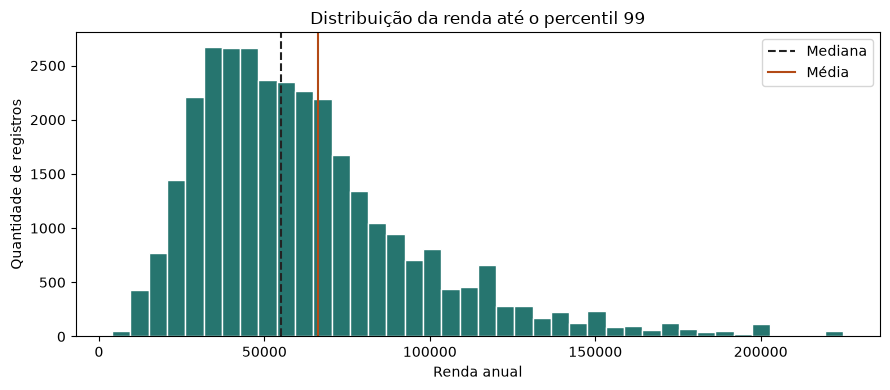

In [6]:
import matplotlib.pyplot as plt

renda = df["person_income"]
limite = renda.quantile(0.99)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(renda[renda <= limite], bins=40, color="#26756F", edgecolor="white")

ax.axvline(renda.median(), color="#222222", linestyle="--", label="Mediana")
ax.axvline(renda.mean(), color="#B34A16", linestyle="-", label="Média")

ax.set_title("Distribuição da renda até o percentil 99")
ax.set_xlabel("Renda anual")
ax.set_ylabel("Quantidade de registros")
ax.legend()

plt.tight_layout()
plt.show()

A média da renda (66.074,85) aparece à direita da mediana (55.000), o que indica a influência das rendas mais altas. Para visualizar melhor as faixas em que os registros se concentram, o histograma exibe as rendas até o percentil 99. A mediana e a média foram calculadas com todos os registros.

Linhas duplicadas: 165


,nulos,percentual_%
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
person_emp_length,895,2.75
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_int_rate,3116,9.56
loan_status,0,0.00
loan_percent_income,0,0.00


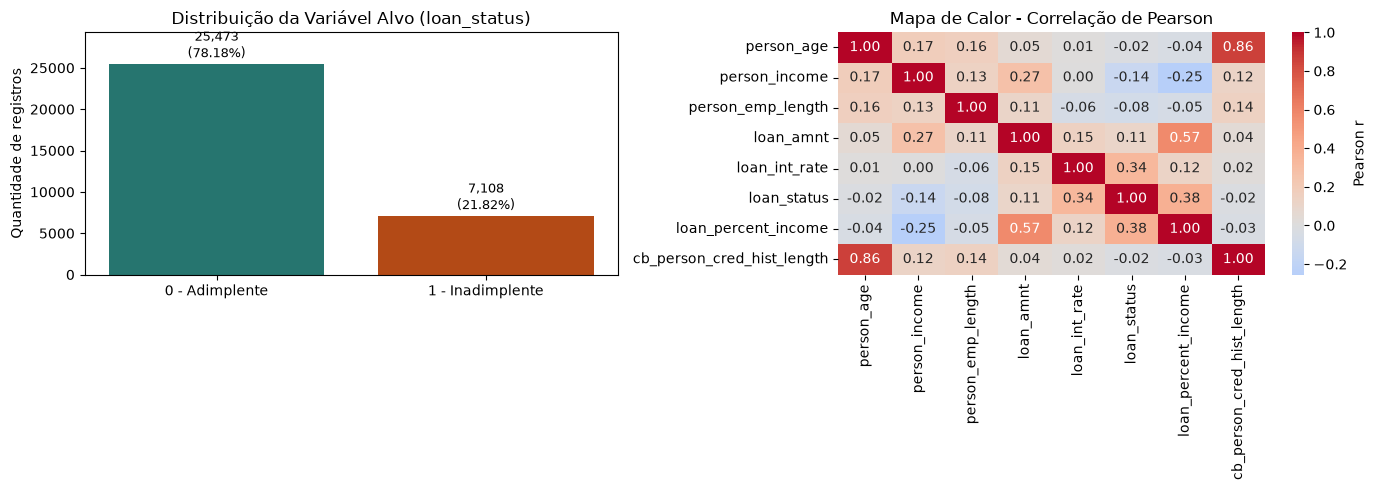

In [7]:
import seaborn as sns

print(f"Linhas duplicadas: {df.duplicated().sum()}")

nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
display(pd.DataFrame({"nulos": nulos, "percentual_%": nulos_pct}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 2: Distribuição da variável alvo
counts = df["loan_status"].value_counts().sort_index()
bars = axes[0].bar(
    ["0 - Adimplente", "1 - Inadimplente"],
    counts.values,
    color=["#26756F", "#B34A16"]
)
axes[0].set_title("Distribuição da Variável Alvo (loan_status)")
axes[0].set_ylabel("Quantidade de registros")
axes[0].set_ylim(0, counts.max() * 1.15)

for bar, qtd in zip(bars, counts.values):
    pct = qtd / len(df) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f"{qtd:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Gráfico 3: Mapa de calor de correlação de Pearson
num_cols = df.select_dtypes(include="number").columns
corr = df[num_cols].corr(method="pearson")
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1],
    cbar_kws={"label": "Pearson r"}
)
axes[1].set_title("Mapa de Calor - Correlação de Pearson")

plt.tight_layout()
plt.show()

### Tomada de decisão (Fase 1 -> Próximas Fases)

A base conta com **32.581 registros** e **12 colunas**, apresentando **165 linhas duplicadas** e valores ausentes em `loan_int_rate` (**3.116 nulos**, 9,56%) e `person_emp_length` (**895 nulos**, 2,75%). A variável alvo `loan_status` é desbalanceada (**78,18%** de adimplentes `0` e **21,82%** de inadimplentes `1`), o que exige `stratify=y` na divisão treino/teste e balanceamento **apenas no conjunto de treino** para evitar *data leakage*.

No mapa de calor de Pearson, `loan_percent_income` (+0,38) e `loan_int_rate` (+0,34) têm as maiores correlações lineares positivas com inadimplência, enquanto `person_age` e `cb_person_cred_hist_length` têm correlação alta entre si (+0,86). Como há assimetria à direita e valores extremos (como `person_income` até 6.000.000, `person_age` até 144 e `person_emp_length` até 123), usaremos a **mediana** onde houver assimetria/outliers e avaliaremos o tratamento de *outliers* na Fase 2 considerando que o **KNN** é sensível a distâncias/outliers e a **Árvore de Decisão** é robusta a eles. Na Fase 3, criaremos `comprometimento_renda = (loan_amnt / person_income) * 100` após tratar os nulos originais.

## Fase 2 — Tratamento e limpeza (Data Prep)

Nesta etapa removemos registros duplicados, tratamos valores ausentes com justificativa estatística e analisamos *outliers* considerando o comportamento do **KNN** e da **Árvore de Decisão**.

Registros antes da remoção de duplicatas: 32581
Linhas duplicadas encontradas: 165
Registros após remover duplicatas: 32416

person_emp_length: 887 nulos | Média = 4.79 | Mediana = 4.00
loan_int_rate: 3095 nulos | Média = 11.02 | Mediana = 10.99


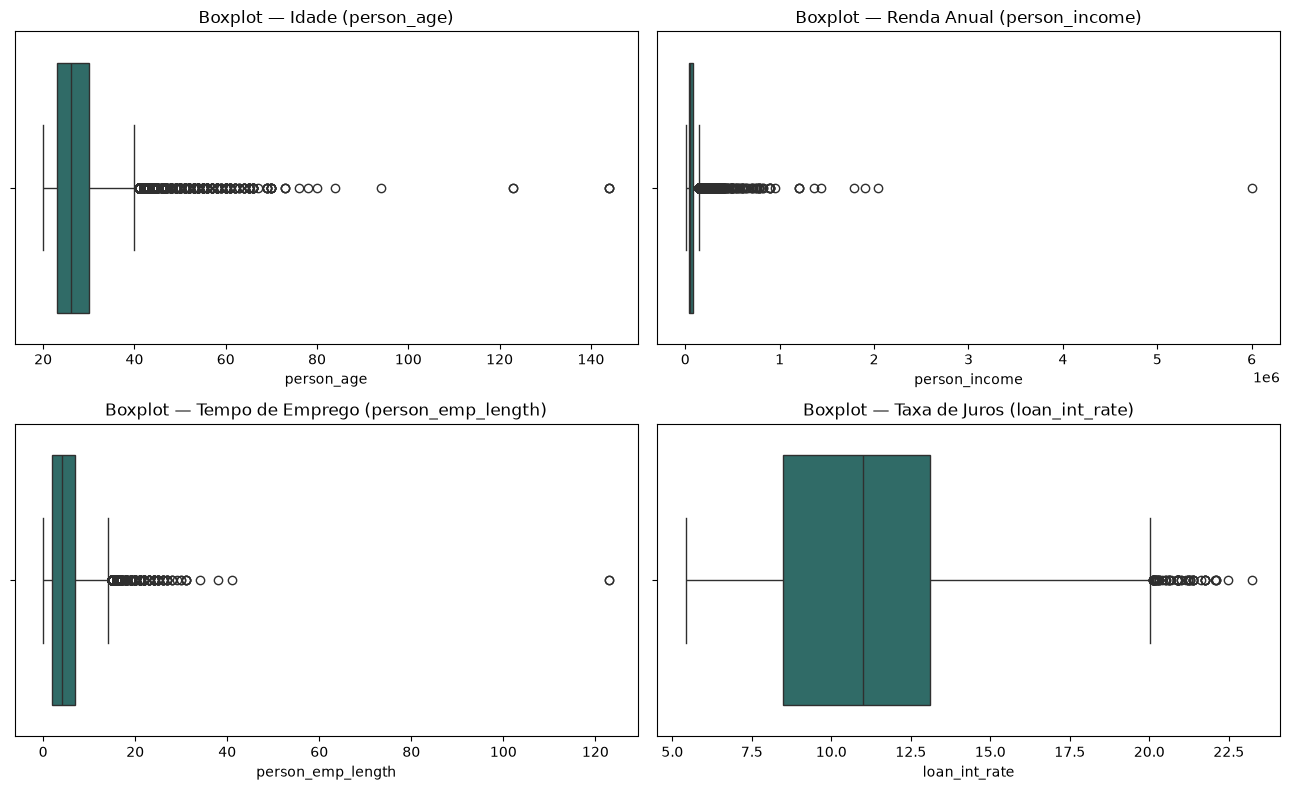


Linhas removidas por inconsistência lógica/extrema: 7
Total de linhas ao final da Fase 2: 32409
Total de valores nulos restantes: 0


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Registros antes da remoção de duplicatas: {len(df)}")
duplicadas = df.duplicated().sum()
print(f"Linhas duplicadas encontradas: {duplicadas}")

df_clean = df.drop_duplicates().copy()
print(f"Registros após remover duplicatas: {len(df_clean)}\n")

# Comparação Média vs. Mediana antes da imputação
for col in ["person_emp_length", "loan_int_rate"]:
    nulos_qtd = df_clean[col].isnull().sum()
    media_val = df_clean[col].mean()
    mediana_val = df_clean[col].median()
    print(f"{col}: {nulos_qtd} nulos | Média = {media_val:.2f} | Mediana = {mediana_val:.2f}")

# Imputação pela mediana
df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(df_clean["person_emp_length"].median())
df_clean["loan_int_rate"] = df_clean["loan_int_rate"].fillna(df_clean["loan_int_rate"].median())

# Boxplots para inspeção de outliers
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
box_vars = [
    ("person_age", "Idade (person_age)"),
    ("person_income", "Renda Anual (person_income)"),
    ("person_emp_length", "Tempo de Emprego (person_emp_length)"),
    ("loan_int_rate", "Taxa de Juros (loan_int_rate)")
]

for ax, (col, titulo) in zip(axes.flat, box_vars):
    sns.boxplot(x=df_clean[col], ax=ax, color="#26756F")
    ax.set_title(f"Boxplot — {titulo}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

# Remoção de inconsistências evidentes (idade > 100, tempo de emprego > 60 ou tempo de emprego >= idade)
antes_filtro = len(df_clean)
df_clean = df_clean[
    (df_clean["person_age"] <= 100) &
    (df_clean["person_emp_length"] <= 60) &
    (df_clean["person_emp_length"] < df_clean["person_age"])
].copy()
print(f"\nLinhas removidas por inconsistência lógica/extrema: {antes_filtro - len(df_clean)}")
print(f"Total de linhas ao final da Fase 2: {len(df_clean)}")
print(f"Total de valores nulos restantes: {df_clean.isnull().sum().sum()}")

### Justificativa de limpeza, imputação e tratamento de outliers

* **Duplicadas:** Foram removidas **165** linhas duplicadas para evitar redundância e viés de frequência durante o treinamento.
* **Valores nulos:** Optamos pela **mediana** tanto para `person_emp_length` (**887** nulos após deduplicação; mediana `4,00` vs. média `4,79`) quanto para `loan_int_rate` (**3.095** nulos após deduplicação; mediana `10,99` vs. média `11,02`), pois a mediana é resistente a assimetrias e valores extremos.
* **Outliers e impacto nos modelos:** Os *boxplots* evidenciam caudas à direita e valores extremos/inconsistentes, como `person_age` até 144, `person_emp_length` até 123 e `person_income` até 6.000.000. Removemos apenas **7** registros com inconsistências lógicas claras (`person_age > 100`, `person_emp_length > 60` ou `person_emp_length >= person_age`), preservando rendas elevadas válidas para não descartar clientes de alta renda. Essa decisão é estratégica: o **KNN** calcula distâncias euclidianas e sofre forte influência de valores extremos (o que reforça a importância do `StandardScaler` na Fase 4), enquanto a **Árvore de Decisão** realiza divisões por limiares e é naturalmente mais robusta a *outliers*.

## Fase 3 — Feature Engineering (Coluna Calculada)

Nesta etapa criamos a variável `comprometimento_renda = (loan_amnt / person_income) * 100` após validar a ausência de nulos e de divisões por zero nas colunas de origem[cite: 4].

In [9]:
import numpy as np

# Garantia de que não há nulos ou divisões por zero nas variáveis de origem
assert df_clean["loan_amnt"].isnull().sum() == 0, "Existem nulos em loan_amnt"
assert df_clean["person_income"].isnull().sum() == 0, "Existem nulos em person_income"
assert (df_clean["person_income"] > 0).all(), "Existem rendas zero ou negativas"

# Criação da coluna calculada exigida para a Base A
df_clean["comprometimento_renda"] = (df_clean["loan_amnt"] / df_clean["person_income"]) * 100

print("Nulos em comprometimento_renda:", df_clean["comprometimento_renda"].isnull().sum())
print("Valores infinitos em comprometimento_renda:", np.isinf(df_clean["comprometimento_renda"]).sum())
print("\nResumo estatístico de comprometimento_renda (%):")
display(df_clean["comprometimento_renda"].describe().to_frame().T.round(2))

print("\nComprometimento de renda (%) por loan_status:")
display(
    df_clean.groupby("loan_status")["comprometimento_renda"]
    .agg(quantidade="count", media="mean", mediana="median", desvio_padrao="std")
    .round(2)
)

Nulos em comprometimento_renda: 0
Valores infinitos em comprometimento_renda: 0

Resumo estatístico de comprometimento_renda (%):


,count,mean,std,min,25%,50%,75%,max
comprometimento_renda,32409.0,17.06,10.71,0.08,8.97,14.81,22.92,83.0



Comprometimento de renda (%) por loan_status:


,quantidade,media,mediana,desvio_padrao
loan_status,,,,
0,25321,14.87,13.33,8.72
1,7088,24.87,23.94,13.20


### Justificativa da Feature (`comprometimento_renda`)

A variável `comprometimento_renda` expressa, em percentual, o quanto o valor do empréstimo (`loan_amnt`) representa frente à renda anual do cliente (`person_income`), após o tratamento prévio dos dados na Fase 2 para evitar valores `NaN` ou infinitos[cite: 4]. Do ponto de vista de risco de crédito, quanto maior o comprometimento de renda, maior tende a ser a pressão sobre o orçamento do cliente e maior o risco de inadimplência — o que se reflete nos dados, com média de **24,87%** entre inadimplentes (`loan_status = 1`) contra **14,87%** entre adimplentes (`loan_status = 0`).